In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0
    time_outputs2 = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            start_time_outputs = time.time()

            outputs = model(inputs, feats)

            time_outputs = time.time()-start_time_outputs
            time_outputs2 += time_outputs

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print('_' * 60)
    print ('       Время выхода с сети: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_outputs2))))
    print ('       Время выхода с сети в секундах: {:.6f}'.format(time_outputs2))

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN) 

    recall_1 = recall_score(actuals, predictions, average='micro')
    recall_2 = recall_score(actuals, predictions, average='macro')
    

    precision_1 = precision_score(actuals, predictions, average='micro')
    precision_2 = precision_score(actuals, predictions, average='macro')


    f1_1 = f1_score(actuals, predictions, average='micro')
    f1_2 = f1_score(actuals, predictions, average='macro')
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')

    accuracy_1 = accuracy_score(actuals, predictions)

    MCC = matthews_corrcoef(actuals, predictions)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    
    print('_' * 60)
    print('Accuracy score: %.2f' % (accuracy_1*100))
    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('Matthews corrcoef: %.4f' % MCC)
    print('F1: %.4f' % F1)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    
    print('_' * 60)
    print('Recall micro: %.4f' % recall_1)
    print('Recall macro: %.4f' % recall_2)
    print('Precision micro: %.4f' % precision_1)
    print('Precision macro: %.4f' % precision_2)
    print('F1 score micro: %.4f' % f1_1)
    print('F1 score macro: %.4f' % f1_2)
    
    print('Jaccard score micro: %.4f' % jaccard_1)
    print('Jaccard score macro: %.4f' % jaccard_2)
    print('Specificity macro: %.4f' % s1)
    print('Specificity weighted: %.4f' % s3)
    
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

In [5]:
data_dir = "C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 227
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [6]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [7]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_15612\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_15612\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metada

In [8]:
metadata

,name,diagnosis,age,sex,anatomloc
0,ISIC_0010512,6,3,0,1
1,ISIC_0010889,6,0,1,0
2,ISIC_0024468,6,3,0,1
3,ISIC_0024470,6,2,0,7
4,ISIC_0024511,6,1,1,1
...,...,...,...,...,...
41720,ISIC_0072937,0,2,1,3
41721,ISIC_0072964,0,0,0,0
41722,ISIC_0073012,0,2,1,3
41723,ISIC_0073031,0,0,1,3


In [9]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

#torch.save(train_indices, 'Parametr\\train_indices.pt')
#torch.save(val_indices, 'Parametr\\val_indices.pt')
#torch.save(test_indices, 'Parametr\\test_indices.pt')

train_indices = torch.load('Parametr\\train_indices2.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices2.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices2.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [10]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [11]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
1. nevus : tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [12]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [01:51<00:00, 374.68it/s]


In [13]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

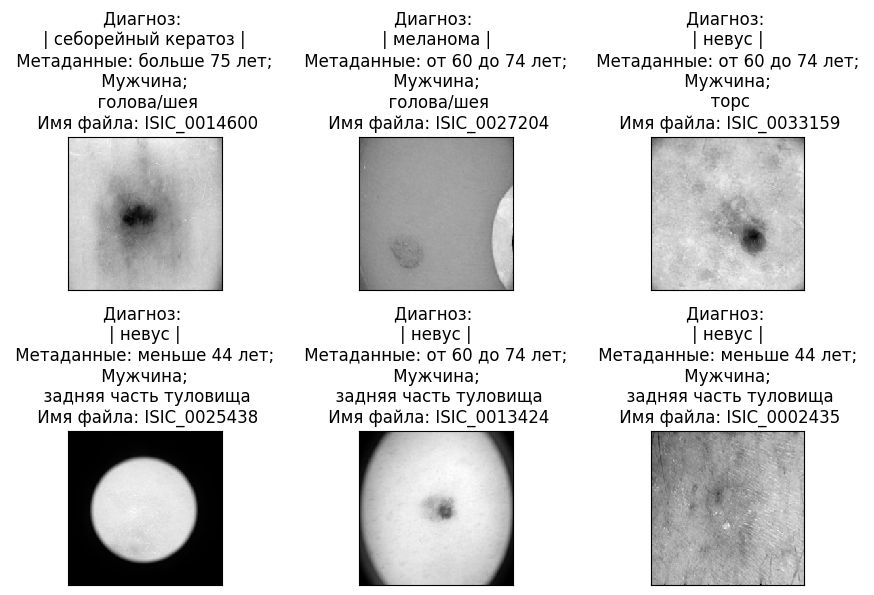

In [14]:
age = ['меньше 44 лет', 'от 45 до 59 лет', 'от 60 до 74 лет', 'больше 75 лет']
sex = ['Мужчина', 'Женщина']
anatomloc = ['торс', 'голова/шея', 'боковая часть туловища', 'нижняя конечность', 'оральная/генитальная зона', 'ладони/подошвы', 'задняя часть туловища', 'верхняя конечность']
lab = ['сосудистое поражение', 'невус', 'солнечное лентиго', 'дерматофиброма', 'себорейный кератоз', 'доброкачественный кератоз', 'актинический кератоз', 'базально-клеточная карцинома', 'плоскоклеточный рак', 'меланома']


examples = enumerate(trainloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

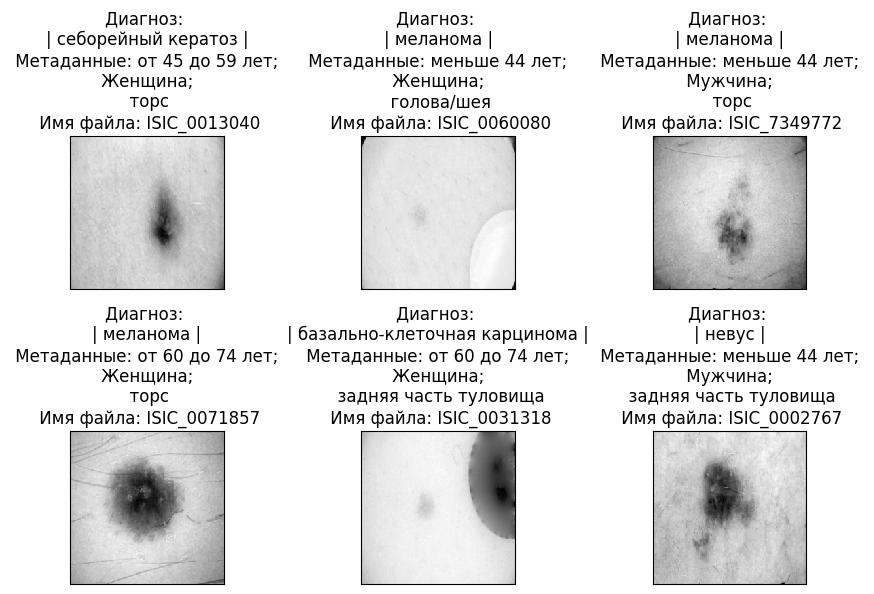

In [15]:
examples = enumerate(valloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

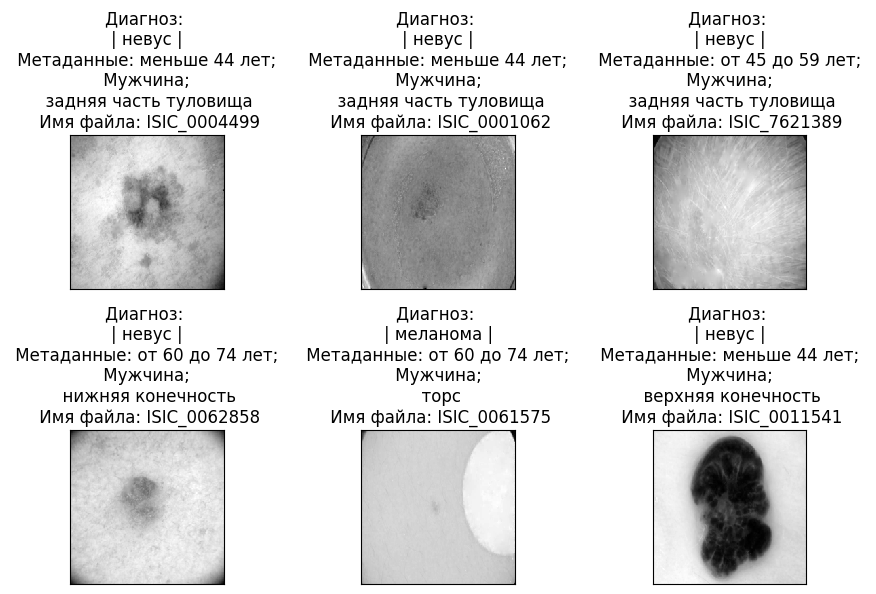

In [16]:
examples = enumerate(testloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

In [17]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(32, 16, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
 
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(16, 14)
      self.fc2 = nn.Linear(14, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_1 = Multimodal_Net.to(device)
NET_light_1

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=16, out_features=14, bias=True)
    (fc2): Linear(in_features=14, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=Tru

In [18]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),
         nn.Conv2d(3, 16, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1)) 
      self.fc1 = nn.Linear(16, 14)
      self.fc2 = nn.Linear(14, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      
      x = self.layer1(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1) 
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_2 = Multimodal_Net.to(device)
NET_light_2

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=16, out_features=14, bias=True)
    (fc2): Linear(in_features=14, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [19]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 128, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(128, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(64, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))       
      self.fc1 = nn.Linear(32, 16)
      self.fc2 = nn.Linear(16, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_3 = Multimodal_Net.to(device)
NET_light_3

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=32, out_features=16, bias=True)
    (fc2): Linear(in_features=16, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=T

In [20]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))         
      self.fc1 = nn.Linear(32, 16)
      self.fc2 = nn.Linear(16, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_4 = Multimodal_Net.to(device)
NET_light_4

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=32, out_features=16, bias=True)
    (fc2): Linear(in_features=16, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [47]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 256, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(256, 128, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(128, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))         
      self.fc1 = nn.Linear(64, 32)
      self.fc2 = nn.Linear(32, 16)
      self.fc3 = nn.Linear(16, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)           
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_5 = Multimodal_Net.to(device)
NET_light_5

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=64, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=16, bias=True)
    (fc3): Linear(in_features=16, out_features=10, bias

In [22]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))        
      self.fc1 = nn.Linear(64, 32)
      self.fc2 = nn.Linear(32, 16)
      self.fc3 = nn.Linear(16, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


Multimodal_Net = Multimodal_Net()
NET_light_6 = Multimodal_Net.to(device)
NET_light_6

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=64, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=16, bias=True)
    (fc3): Linear(in_features=16, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [23]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),         
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x

Multimodal_Net = Multimodal_Net()
NET_light_7 = Multimodal_Net.to(device)
NET_light_7

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, 

In [24]:
total_params_light_1 = "{:,}".format(sum(p.numel() for p in NET_light_1.parameters()))
print(f"NET_light_64/32/16 параметры: {total_params_light_1}")
total_params_light_2 = "{:,}".format(sum(p.numel() for p in NET_light_2.parameters()))
print(f"NET_light_16 параметры: {total_params_light_2}")
total_params_light_3 = "{:,}".format(sum(p.numel() for p in NET_light_3.parameters()))
print(f"NET_light_128/64/32 параметры: {total_params_light_3}")
total_params_light_4 = "{:,}".format(sum(p.numel() for p in NET_light_4.parameters()))
print(f"NET_light_32 параметры: {total_params_light_4}")
total_params_light_5 = "{:,}".format(sum(p.numel() for p in NET_light_5.parameters()))
print(f"NET_light_256/128/64 параметры: {total_params_light_5}")
total_params_light_6 = "{:,}".format(sum(p.numel() for p in NET_light_6.parameters()))
print(f"NET_light_64 параметры: {total_params_light_6}")
total_params_light_7 = "{:,}".format(sum(p.numel() for p in NET_light_7.parameters()))
print(f"NET_light_ИЗНАЧАЛЬНАЯ параметры: {total_params_light_7}")

NET_light_64/32/16 параметры: 29,604
NET_light_16 параметры: 5,172
NET_light_128/64/32 параметры: 100,878
NET_light_32 параметры: 5,934
NET_light_256/128/64 параметры: 382,954
NET_light_64 параметры: 8,746
NET_light_ИЗНАЧАЛЬНАЯ параметры: 268,794


In [25]:
def train_and_evaluate(model, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, num_epochs=20):

    start_time_glob = time.time()
    model.train()
    
    best_model_wts = copy.deepcopy(model.state_dict())
    
    best_acc = 0.0
    
    for epoch in range(num_epochs):
        
        model.train()
        start_time_tarin = time.time()
        
        print('_' * 120)
        print('Эпоха {}/{}\n'.format(epoch+1, num_epochs))
        
        running_loss = 0.0
        running_corrects = 0
        train_accuracy = 0
        total = 0
        correct_train = 0
        
        for i, data in enumerate(trainloader):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs, feats)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            loss.backward() 
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

            correct_train += preds.eq(labels.data.view_as(preds)).sum()

            total += labels.size(0)
            train_accuracy = 100 * running_corrects / total
            train_accuracy = train_accuracy.cpu()

            if i % 100 == 0:
                print('Тренировочная эпоха: {} [{}/{} ({:.0f}%)]\t\t | Ошибка: {:.4f}\t | Точность распознавания: {:.2f}%'.format(epoch+1, batch_size * i, len_trainset, 100 * i / len(trainloader), loss.item(), train_accuracy))
                
                train_counter.append((i*batch_size) + ((epoch)*len_trainset))
                train_losses.append(loss.item())
                train_acc.append(train_accuracy)
                
        epoch_loss = running_loss / len_trainset
        epoch_acc = running_corrects.double() / len_trainset
        
        time_tarin = time.time()-start_time_tarin
        
        print('\n   Тренировочная ошибка: {:.4f} Точность: {}/{} ({:.2f}%)'.format(epoch_loss, correct_train, len_trainset, 100 * epoch_acc))
        print ('        Время обучения: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_tarin))))
      
        model.eval()
        start_time_test = time.time()
        
        running_loss_val = 0.0 
        running_corrects_val = 0
        correct = 0
        
        with torch.no_grad():
            
            for data in valloader:
                
                inputs, feats, labels, name = data
                inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
            
                outputs = model(inputs, feats)
            
                loss = criterion(outputs,labels)
                _, preds = torch.max(outputs, 1)

                correct += preds.eq(labels.data.view_as(preds)).sum()
            
                running_loss_val += loss.item() * inputs.size(0)
                running_corrects_val += torch.sum(preds == labels.data)
        
            epoch_loss_val = running_loss_val / len_valset
            epoch_acc_val = running_corrects_val.double() / len_valset
            epoch_acc_val_2 = 100 * epoch_acc_val.cpu()

            test_losses.append(epoch_loss_val)
            test_acc.append(epoch_acc_val_2)

            time_test = time.time()-start_time_test
        
            if epoch_acc_val > best_acc:
                best_acc = epoch_acc_val
                best_model_wts = copy.deepcopy(model.state_dict())
            
                torch.save(model.state_dict(), f"BestModel_teacher.pth")

            print('   Валидационная ошибка: {:.4f} Точность: {}/{} ({:.2f}%)'.format(epoch_loss_val, correct, len_valset, 100 * epoch_acc_val))
            print ('        Время тестирования: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
        
            print('Лучшая валидационная точность: {:.4f}'.format(best_acc))

            torch.save(model.state_dict(), f"teacher_epoch-{epoch+1}.pth")
            model.load_state_dict(best_model_wts)

    time_glob = time.time()-start_time_glob
    print('_' * 120)
    print ('\nОбщее время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    
    return model

In [26]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_1.parameters(), lr=0.001, momentum=0.9)

NET_light_64_32_16 = train_and_evaluate(NET_light_1, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.4588	 | Точность распознавания: 6.25%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.7251	 | Точность распознавания: 42.64%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.3087	 | Точность распознавания: 54.46%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.1764	 | Точность распознавания: 58.59%

   Тренировочная ошибка: 1.4673 Точность: 15131/25035 (60.44%)
        Время обучения: 00:00:30

   Валидационная ошибка: 1.0515 Точность: 5601/8345 (67.12%)
        Время тестирования: 00:00:05

Лучшая валидационная точность: 0.6712
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 1.0125	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/25

In [27]:
torch.save(train_losses, 'NET_light_64_32_16\\train_losses.pt')
torch.save(train_counter, 'NET_light_64_32_16\\train_counter.pt')
torch.save(train_acc, 'NET_light_64_32_16\\train_acc.pt')

torch.save(test_losses, 'NET_light_64_32_16\\test_losses.pt')
torch.save(test_counter, 'NET_light_64_32_16\\test_counter.pt')
torch.save(test_acc, 'NET_light_64_32_16\\test_acc.pt')

torch.save(NET_light_64_32_16.state_dict(), 'NET_light_64_32_16\\NET_light_64_32_16.pt')

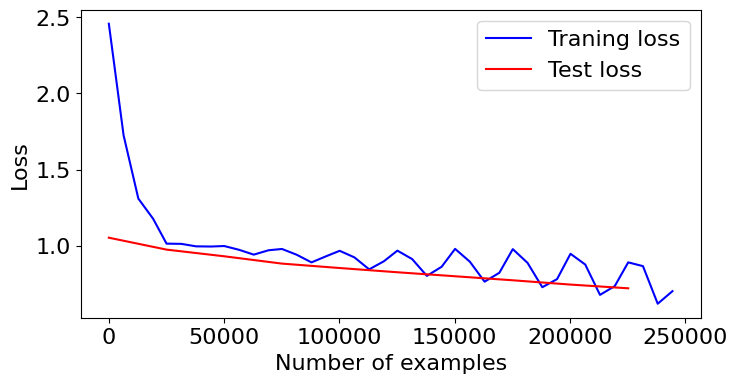

<Figure size 640x480 with 0 Axes>

In [28]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

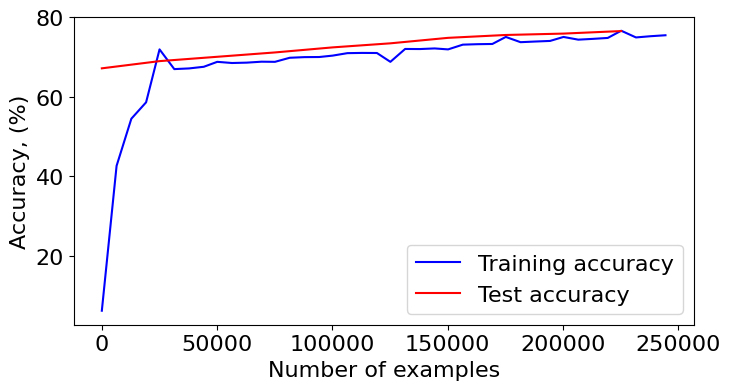

<Figure size 640x480 with 0 Axes>

In [29]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:06
Время тестирования в секундах: 6.592833



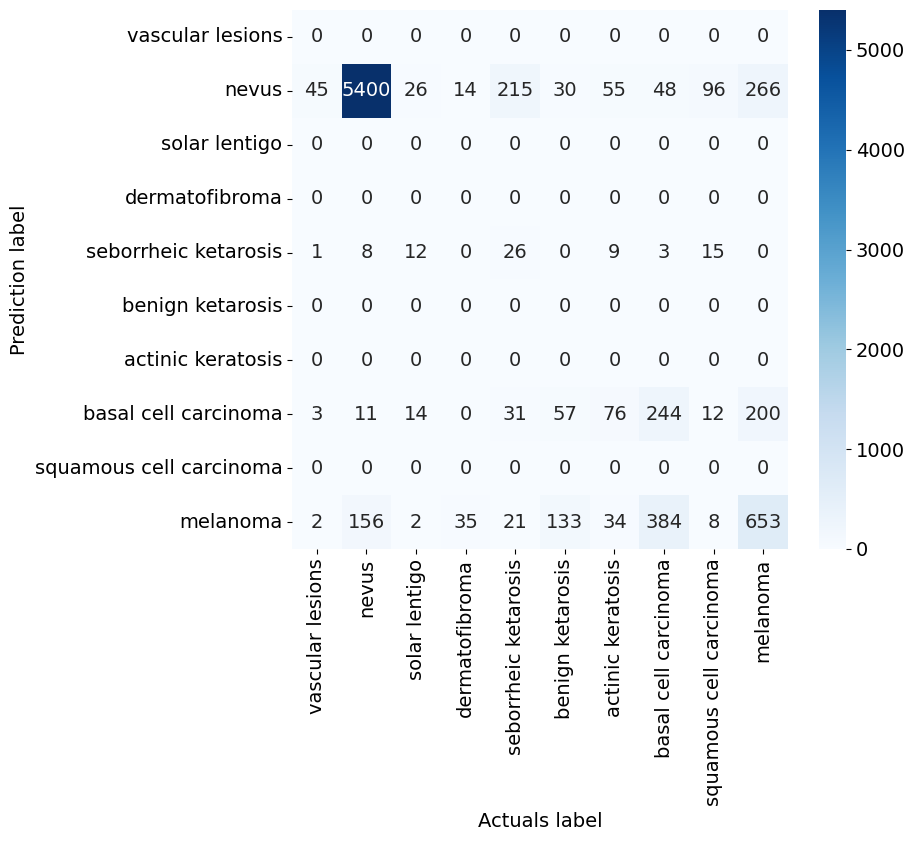

____________________________________________________________
Accuracy score: 75.77
Sensitivity: 0.7577
Specificity: 0.9731
Matthews corrcoef: 0.4977
F1: 0.7577
NPV: 0.9731
PPV: 0.7577
FNR: 0.2423
FPR: 0.0269
____________________________________________________________
Recall micro: 0.7577
Recall macro: 0.2000
Precision micro: 0.7577
Precision macro: 0.2057
F1 score micro: 0.7577
F1 score macro: 0.1940
Jaccard score micro: 0.6099
Jaccard score macro: 0.1494
Specificity macro: 0.9547
Specificity weighted: 0.7894
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7130
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9940
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9473
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [30]:
actuals = []
predictions = []

test_NN(NET_light_64_32_16, testloader)

torch.save(actuals, 'NET_light_64_32_16\\actuals.pt')
torch.save(predictions, 'NET_light_64_32_16\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_64_32_16\\matrix.pt')

test_metric()

In [31]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_2.parameters(), lr=0.001, momentum=0.9)

NET_light_16 = train_and_evaluate(NET_light_2, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.2677	 | Точность распознавания: 12.50%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.5682	 | Точность распознавания: 57.55%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.3167	 | Точность распознавания: 61.96%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.1261	 | Точность распознавания: 63.61%

   Тренировочная ошибка: 1.3939 Точность: 16122/25035 (64.40%)
        Время обучения: 00:00:19

   Валидационная ошибка: 1.0521 Точность: 5681/8345 (68.08%)
        Время тестирования: 00:00:04

Лучшая валидационная точность: 0.6808
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 1.0071	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/2

In [32]:
torch.save(train_losses, 'NET_light_16\\train_losses.pt')
torch.save(train_counter, 'NET_light_16\\train_counter.pt')
torch.save(train_acc, 'NET_light_16\\train_acc.pt')

torch.save(test_losses, 'NET_light_16\\test_losses.pt')
torch.save(test_counter, 'NET_light_16\\test_counter.pt')
torch.save(test_acc, 'NET_light_16\\test_acc.pt')

torch.save(NET_light_16.state_dict(), 'NET_light_16\\NET_light_16.pt')

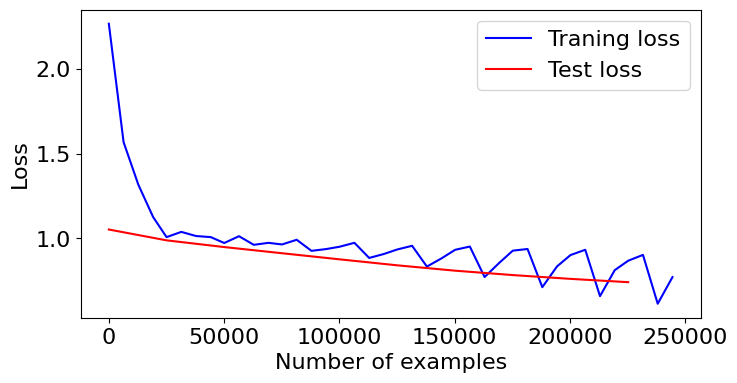

<Figure size 640x480 with 0 Axes>

In [33]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

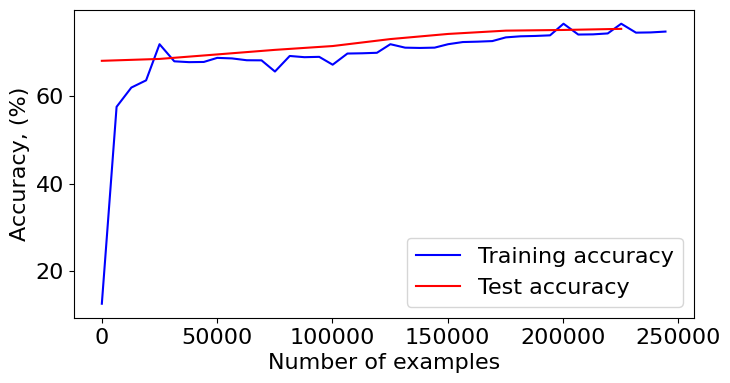

<Figure size 640x480 with 0 Axes>

In [34]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.135876



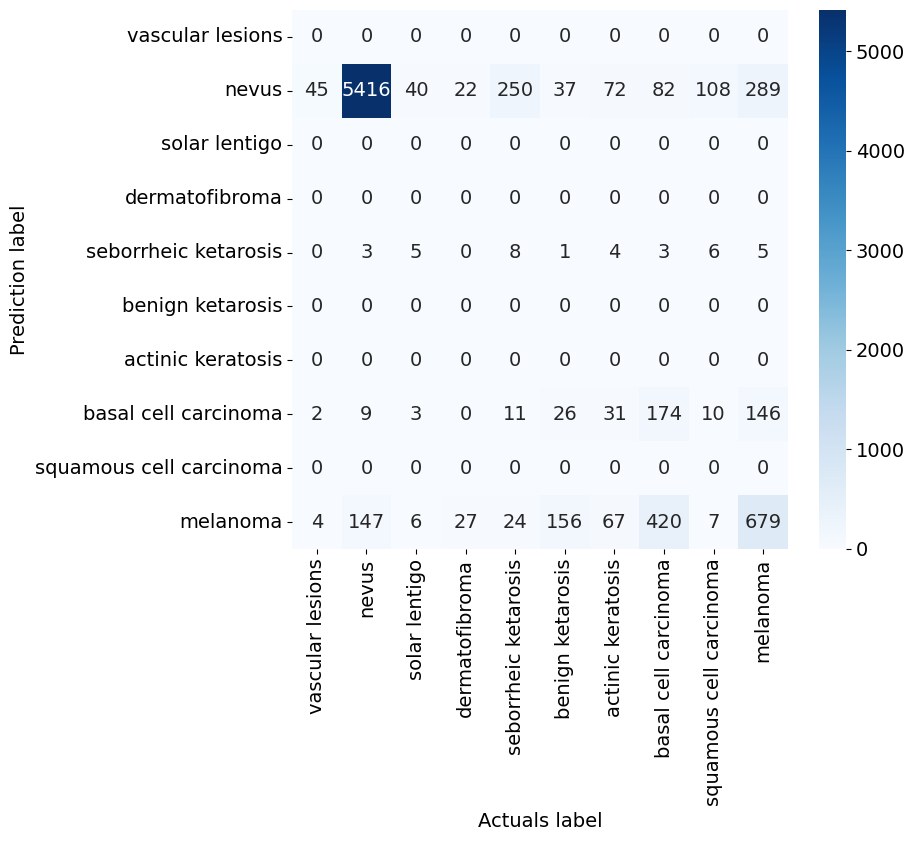

____________________________________________________________
Accuracy score: 75.22
Sensitivity: 0.7522
Specificity: 0.9725
Matthews corrcoef: 0.4771
F1: 0.7522
NPV: 0.9725
PPV: 0.7522
FNR: 0.2478
FPR: 0.0275
____________________________________________________________
Recall micro: 0.7522
Recall macro: 0.1862
Precision micro: 0.7522
Precision macro: 0.1944
F1 score micro: 0.7522
F1 score macro: 0.1787
Jaccard score micro: 0.6028
Jaccard score macro: 0.1389
Specificity macro: 0.9506
Specificity weighted: 0.7535
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6588
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9966
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9690
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
actuals = []
predictions = []

test_NN(NET_light_16, testloader)

torch.save(actuals, 'NET_light_16\\actuals.pt')
torch.save(predictions, 'NET_light_16\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_16\\matrix.pt')

test_metric()

In [36]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_3.parameters(), lr=0.001, momentum=0.9)

NET_light_128_64_32 = train_and_evaluate(NET_light_3, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.4347	 | Точность распознавания: 0.00%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.6549	 | Точность распознавания: 42.59%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.1573	 | Точность распознавания: 54.44%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.0599	 | Точность распознавания: 58.57%

   Тренировочная ошибка: 1.4215 Точность: 15128/25035 (60.43%)
        Время обучения: 00:00:45

   Валидационная ошибка: 1.0402 Точность: 5601/8345 (67.12%)
        Время тестирования: 00:00:07

Лучшая валидационная точность: 0.6712
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.9659	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/25

In [37]:
torch.save(train_losses, 'NET_light_128_64_32\\train_losses.pt')
torch.save(train_counter, 'NET_light_128_64_32\\train_counter.pt')
torch.save(train_acc, 'NET_light_128_64_32\\train_acc.pt')

torch.save(test_losses, 'NET_light_128_64_32\\test_losses.pt')
torch.save(test_counter, 'NET_light_128_64_32\\test_counter.pt')
torch.save(test_acc, 'NET_light_128_64_32\\test_acc.pt')

torch.save(NET_light_128_64_32.state_dict(), 'NET_light_128_64_32\\NET_light_128_64_32.pt')

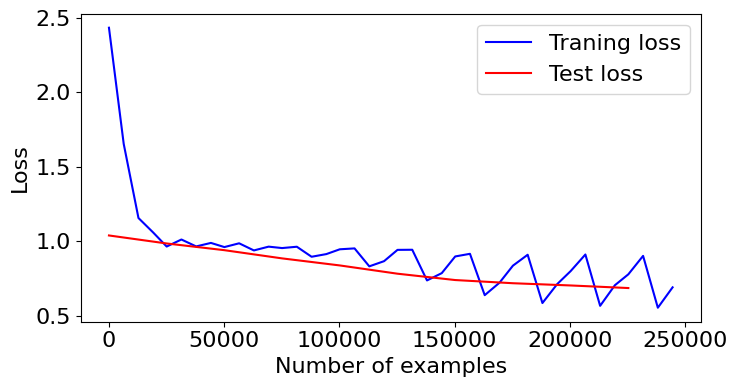

<Figure size 640x480 with 0 Axes>

In [38]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

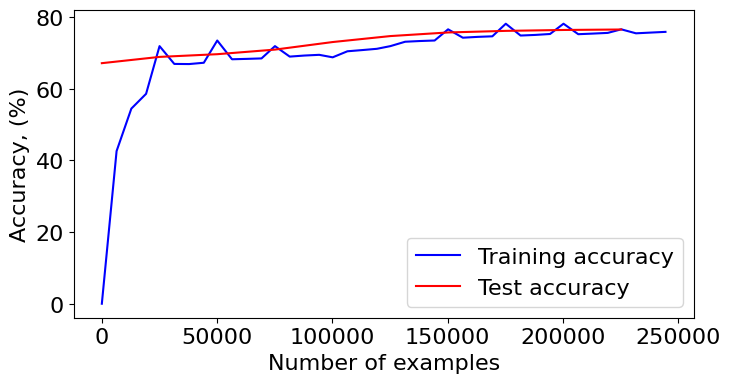

<Figure size 640x480 with 0 Axes>

In [39]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:08
Время тестирования в секундах: 8.192883



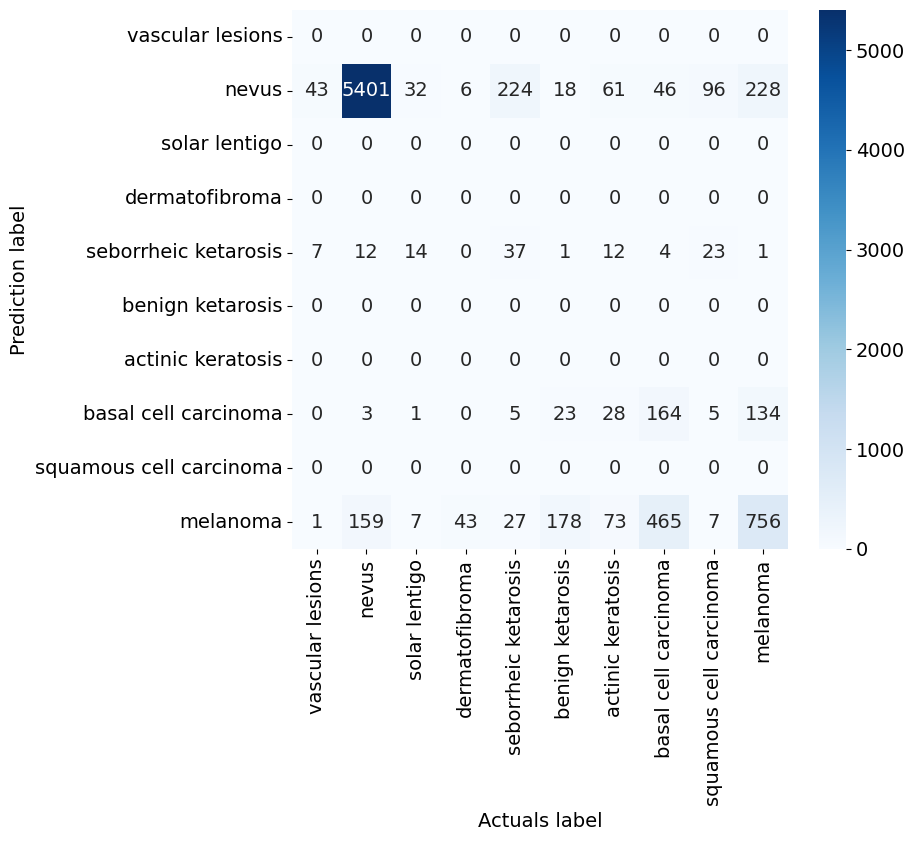

____________________________________________________________
Accuracy score: 76.19
Sensitivity: 0.7619
Specificity: 0.9735
Matthews corrcoef: 0.5104
F1: 0.7619
NPV: 0.9735
PPV: 0.7619
FNR: 0.2381
FPR: 0.0265
____________________________________________________________
Recall micro: 0.7619
Recall macro: 0.2012
Precision micro: 0.7619
Precision macro: 0.2103
F1 score micro: 0.7619
F1 score macro: 0.1952
Jaccard score micro: 0.6154
Jaccard score macro: 0.1505
Specificity macro: 0.9560
Specificity weighted: 0.7979
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7278
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9908
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9740
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [40]:
actuals = []
predictions = []

test_NN(NET_light_128_64_32, testloader)

torch.save(actuals, 'NET_light_128_64_32\\actuals.pt')
torch.save(predictions, 'NET_light_128_64_32\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_128_64_32\\matrix.pt')

test_metric()

In [41]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_4.parameters(), lr=0.001, momentum=0.9)

NET_light_32 = train_and_evaluate(NET_light_4, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.2937	 | Точность распознавания: 1.56%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.2223	 | Точность распознавания: 59.67%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.1335	 | Точность распознавания: 63.02%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.0552	 | Точность распознавания: 64.30%

   Тренировочная ошибка: 1.2842 Точность: 16232/25035 (64.84%)
        Время обучения: 00:00:21

   Валидационная ошибка: 1.0079 Точность: 5601/8345 (67.12%)
        Время тестирования: 00:00:05

Лучшая валидационная точность: 0.6712
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.9573	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/25

In [42]:
torch.save(train_losses, 'NET_light_32\\train_losses.pt')
torch.save(train_counter, 'NET_light_32\\train_counter.pt')
torch.save(train_acc, 'NET_light_32\\train_acc.pt')

torch.save(test_losses, 'NET_light_32\\test_losses.pt')
torch.save(test_counter, 'NET_light_32\\test_counter.pt')
torch.save(test_acc, 'NET_light_32\\test_acc.pt')

torch.save(NET_light_32.state_dict(), 'NET_light_32\\NET_light_32.pt')

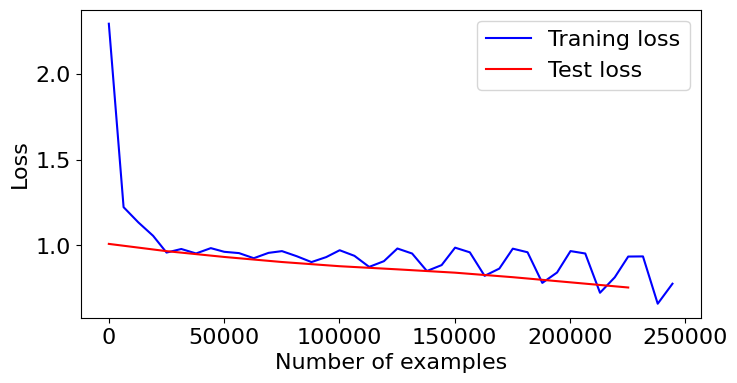

<Figure size 640x480 with 0 Axes>

In [43]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

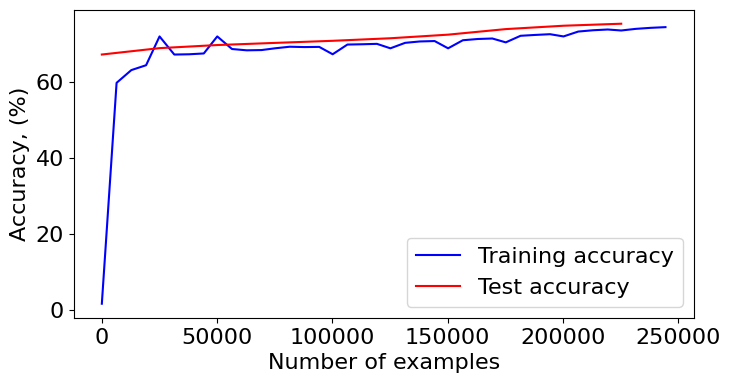

<Figure size 640x480 with 0 Axes>

In [44]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.839286



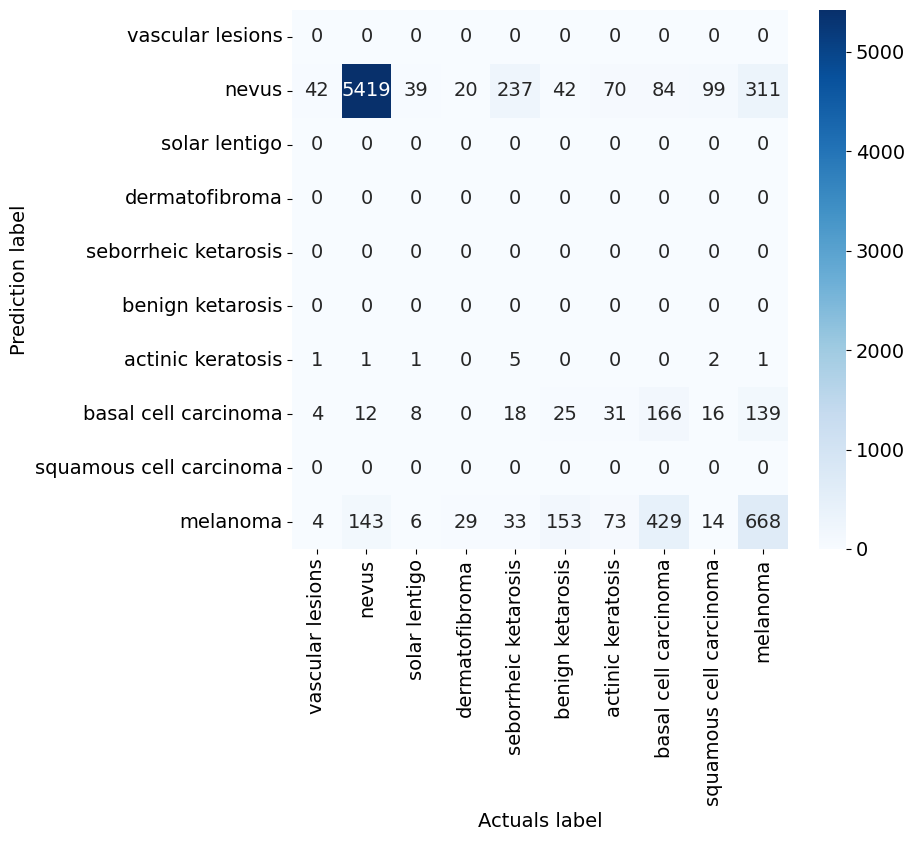

____________________________________________________________
Accuracy score: 74.93
Sensitivity: 0.7493
Specificity: 0.9721
Matthews corrcoef: 0.4706
F1: 0.7493
NPV: 0.9721
PPV: 0.7493
FNR: 0.2507
FPR: 0.0279
____________________________________________________________
Recall micro: 0.7493
Recall macro: 0.1813
Precision micro: 0.7493
Precision macro: 0.1678
F1 score micro: 0.7493
F1 score macro: 0.1710
Jaccard score micro: 0.5991
Jaccard score macro: 0.1343
Specificity macro: 0.9503
Specificity weighted: 0.7532
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6592
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 1.0000
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9987
Specificity none - class basal cell carcinoma (7): 0.9670
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [45]:
actuals = []
predictions = []

test_NN(NET_light_32, testloader)

torch.save(actuals, 'NET_light_32\\actuals.pt')
torch.save(predictions, 'NET_light_32\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_32\\matrix.pt')

test_metric()

In [48]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_5.parameters(), lr=0.001, momentum=0.9)

NET_light_256_128_64 = train_and_evaluate(NET_light_5, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.1415	 | Точность распознавания: 50.00%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.4601	 | Точность распознавания: 65.86%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.2659	 | Точность распознавания: 66.13%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.1345	 | Точность распознавания: 66.38%

   Тренировочная ошибка: 1.3503 Точность: 16632/25035 (66.43%)
        Время обучения: 00:07:42

   Валидационная ошибка: 1.0410 Точность: 5601/8345 (67.12%)
        Время тестирования: 00:00:12

Лучшая валидационная точность: 0.6712
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.9814	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/2

In [49]:
torch.save(train_losses, 'NET_light_256_128_64\\train_losses.pt')
torch.save(train_counter, 'NET_light_256_128_64\\train_counter.pt')
torch.save(train_acc, 'NET_light_256_128_64\\train_acc.pt')

torch.save(test_losses, 'NET_light_256_128_64\\test_losses.pt')
torch.save(test_counter, 'NET_light_256_128_64\\test_counter.pt')
torch.save(test_acc, 'NET_light_256_128_64\\test_acc.pt')

torch.save(NET_light_256_128_64.state_dict(), 'NET_light_256_128_64\\NET_light_256_128_64.pt')

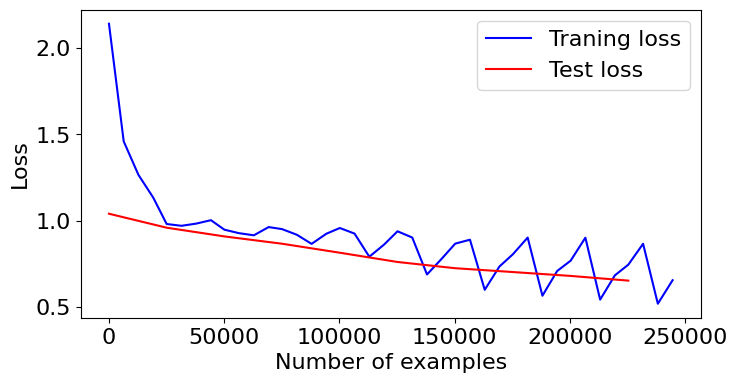

<Figure size 640x480 with 0 Axes>

In [50]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

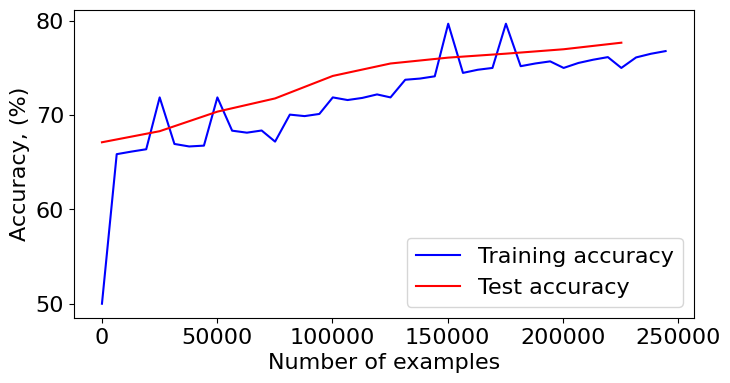

<Figure size 640x480 with 0 Axes>

In [51]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:13
Время тестирования в секундах: 13.653038



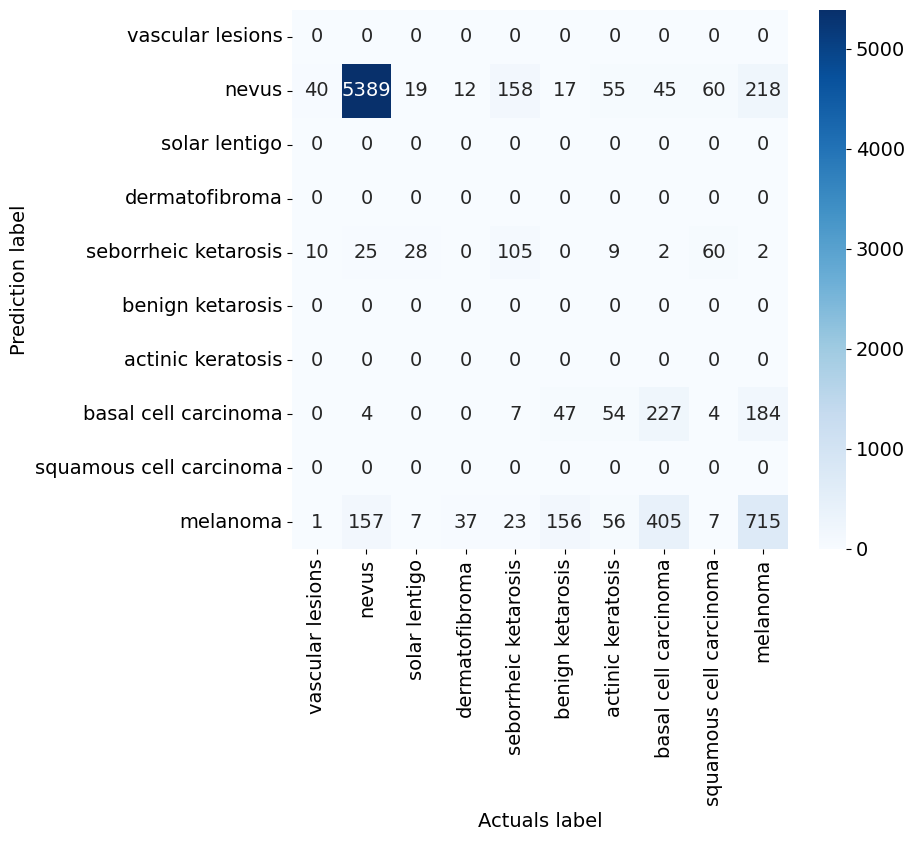

____________________________________________________________
Accuracy score: 77.12
Sensitivity: 0.7712
Specificity: 0.9746
Matthews corrcoef: 0.5368
F1: 0.7712
NPV: 0.9746
PPV: 0.7712
FNR: 0.2288
FPR: 0.0254
____________________________________________________________
Recall micro: 0.7712
Recall macro: 0.2298
Precision micro: 0.7712
Precision macro: 0.2220
F1 score micro: 0.7712
F1 score macro: 0.2233
Jaccard score micro: 0.6277
Jaccard score macro: 0.1709
Specificity macro: 0.9601
Specificity weighted: 0.8300
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7747
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9831
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9609
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [52]:
actuals = []
predictions = []

test_NN(NET_light_256_128_64, testloader)

torch.save(actuals, 'NET_light_256_128_64\\actuals.pt')
torch.save(predictions, 'NET_light_256_128_64\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_256_128_64\\matrix.pt')

test_metric()

In [53]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_6.parameters(), lr=0.001, momentum=0.9)

NET_light_64 = train_and_evaluate(NET_light_6, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.4264	 | Точность распознавания: 3.12%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.7858	 | Точность распознавания: 38.60%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.3084	 | Точность распознавания: 52.43%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.1541	 | Точность распознавания: 57.23%

   Тренировочная ошибка: 1.4630 Точность: 14870/25035 (59.40%)
        Время обучения: 00:00:25

   Валидационная ошибка: 1.0329 Точность: 5601/8345 (67.12%)
        Время тестирования: 00:00:05

Лучшая валидационная точность: 0.6712
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.9760	 | Точность распознавания: 71.88%
Тренировочная эпоха: 2 [6400/25

In [54]:
torch.save(train_losses, 'NET_light_64\\train_losses.pt')
torch.save(train_counter, 'NET_light_64\\train_counter.pt')
torch.save(train_acc, 'NET_light_64\\train_acc.pt')

torch.save(test_losses, 'NET_light_64\\test_losses.pt')
torch.save(test_counter, 'NET_light_64\\test_counter.pt')
torch.save(test_acc, 'NET_light_64\\test_acc.pt')

torch.save(NET_light_64.state_dict(), 'NET_light_64\\NET_light_64.pt')

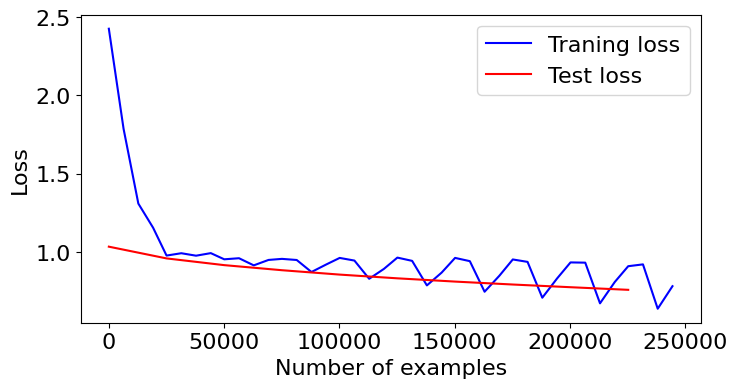

<Figure size 640x480 with 0 Axes>

In [55]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

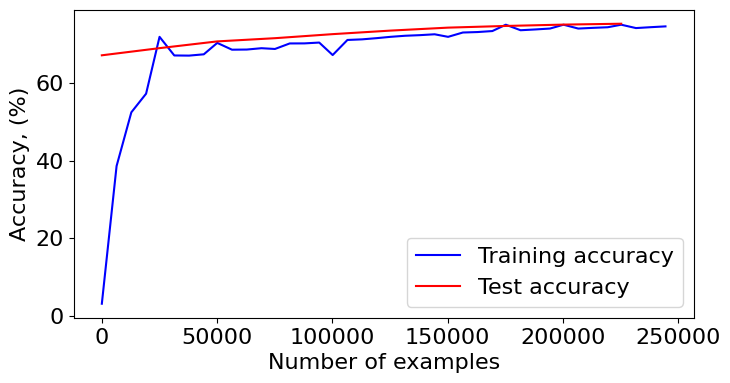

<Figure size 640x480 with 0 Axes>

In [56]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.803180



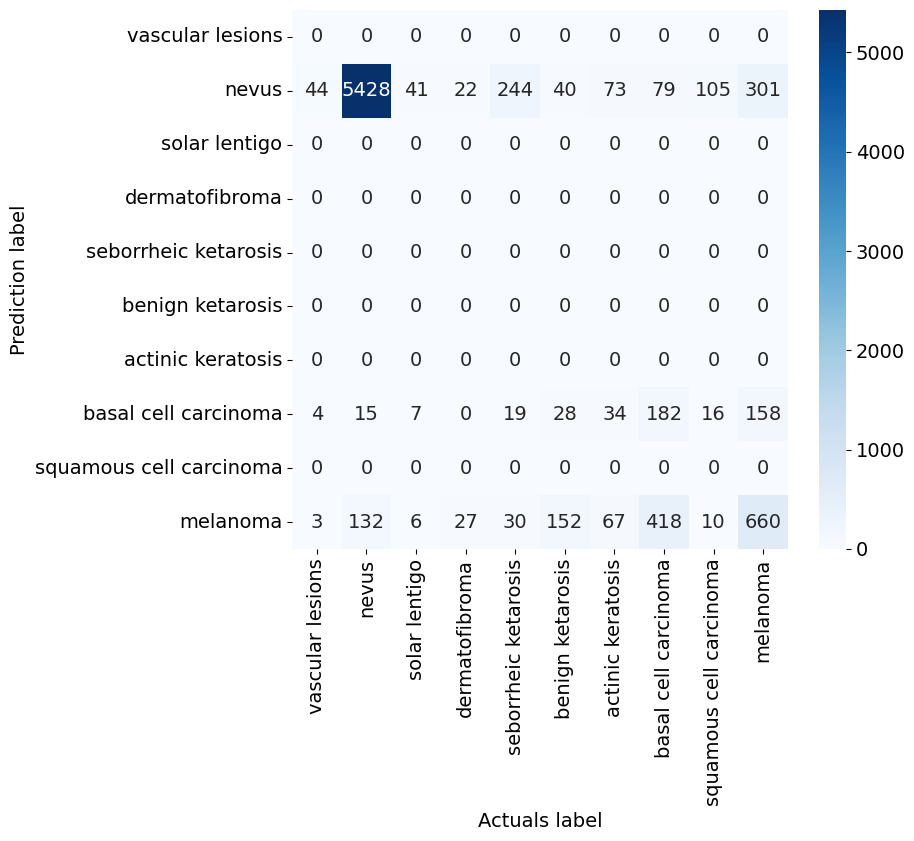

____________________________________________________________
Accuracy score: 75.13
Sensitivity: 0.7513
Specificity: 0.9724
Matthews corrcoef: 0.4741
F1: 0.7513
NPV: 0.9724
PPV: 0.7513
FNR: 0.2487
FPR: 0.0276
____________________________________________________________
Recall micro: 0.7513
Recall macro: 0.1831
Precision micro: 0.7513
Precision macro: 0.1683
F1 score micro: 0.7513
F1 score macro: 0.1730
Jaccard score micro: 0.6017
Jaccard score macro: 0.1358
Specificity macro: 0.9504
Specificity weighted: 0.7525
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6574
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 1.0000
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9633
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [57]:
actuals = []
predictions = []

test_NN(NET_light_64, testloader)

torch.save(actuals, 'NET_light_64\\actuals.pt')
torch.save(predictions, 'NET_light_64\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_64\\matrix.pt')

test_metric()

In [58]:
NET_light_7

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, 

In [59]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(NET_light_7.parameters(), lr=0.001, momentum=0.9)

NET_light_NACH = train_and_evaluate(NET_light_7, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.3334	 | Точность распознавания: 3.12%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 1.6410	 | Точность распознавания: 45.28%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 1.1304	 | Точность распознавания: 55.79%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.0268	 | Точность распознавания: 59.55%

   Тренировочная ошибка: 1.3793 Точность: 15377/25035 (61.42%)
        Время обучения: 00:01:05

   Валидационная ошибка: 1.0059 Точность: 5744/8345 (68.83%)
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.6883
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.9780	 | Точность распознавания: 73.44%
Тренировочная эпоха: 2 [6400/25

In [61]:
torch.save(train_losses, 'NET_light_NACH\\train_losses.pt')
torch.save(train_counter, 'NET_light_NACH\\train_counter.pt')
torch.save(train_acc, 'NET_light_NACH\\train_acc.pt')

torch.save(test_losses, 'NET_light_NACH\\test_losses.pt')
torch.save(test_counter, 'NET_light_NACH\\test_counter.pt')
torch.save(test_acc, 'NET_light_NACH\\test_acc.pt')

torch.save(NET_light_NACH.state_dict(), 'NET_light_NACH\\NET_light_NACH.pt')

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.315177



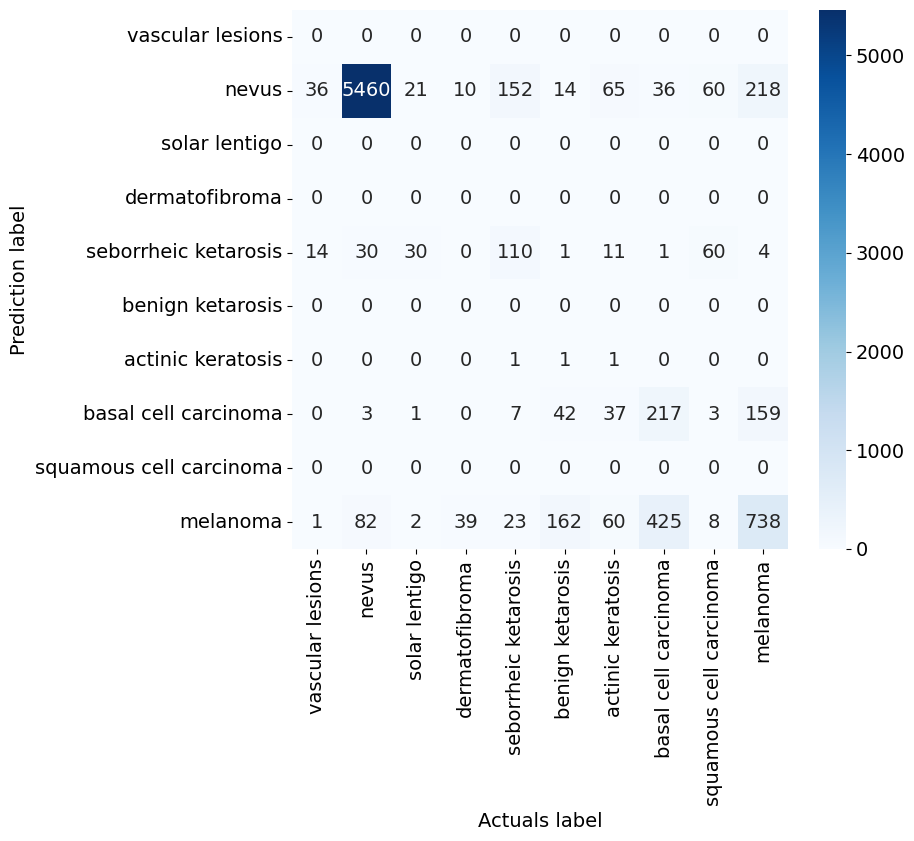

____________________________________________________________
Accuracy score: 78.20
Sensitivity: 0.7820
Specificity: 0.9758
Matthews corrcoef: 0.5565
F1: 0.7820
NPV: 0.9758
PPV: 0.7820
FNR: 0.2180
FPR: 0.0242
____________________________________________________________
Recall micro: 0.7820
Recall macro: 0.2340
Precision micro: 0.7820
Precision macro: 0.2596
F1 score micro: 0.7820
F1 score macro: 0.2279
Jaccard score micro: 0.6421
Jaccard score macro: 0.1753
Specificity macro: 0.9616
Specificity weighted: 0.8342
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7791
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9812
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9998
Specificity none - class basal cell carcinoma (7): 0.9671
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [66]:
actuals = []
predictions = []

test_NN(NET_light_NACH, testloader)

torch.save(actuals, 'NET_light_NACH\\actuals.pt')
torch.save(predictions, 'NET_light_NACH\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light_NACH\\matrix.pt')

test_metric()

In [64]:
test_1 = test(NET_light_NACH, valloader, device)
print(f"Точность изначальной модели: {test_1:.2f}%")

test_2 = test(NET_light_64_32_16, valloader, device)
print(f"Точность модели 64_32_16: {test_2:.2f}%")

test_3 = test(NET_light_16, valloader, device)
print(f"Точность модели 16: {test_3:.2f}%")

test_4 = test(NET_light_128_64_32, valloader, device)
print(f"Точность модели 128_64_32: {test_4:.2f}%")

test_5 = test(NET_light_32, valloader, device)
print(f"Точность модели 32: {test_5:.2f}%")

test_6 = test(NET_light_256_128_64, valloader, device)
print(f"Точность модели 256_128_64: {test_6:.2f}%")

test_7 = test(NET_light_64, valloader, device)
print(f"Точность модели 64: {test_7:.2f}%")

____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.183824
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.694550

Точность изначальной модели: 78.50%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.138742
____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.989612

Точность модели 64_32_16: 76.48%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.110600
____________________________________________________________
Время тестирования: 00:00:04
Время тестирования в секундах: 4.614783

Точность модели 16: 75.39%
____________________________________________________________
       Врем

In [65]:
test_1 = test(NET_light_NACH, testloader, device)
print(f"Точность изначальной модели: {test_1:.2f}%")

test_2 = test(NET_light_64_32_16, testloader, device)
print(f"Точность модели 64_32_16: {test_2:.2f}%")

test_3 = test(NET_light_16, testloader, device)
print(f"Точность модели 16: {test_3:.2f}%")

test_4 = test(NET_light_128_64_32, testloader, device)
print(f"Точность модели 128_64_32: {test_4:.2f}%")

test_5 = test(NET_light_32, testloader, device)
print(f"Точность модели 32: {test_5:.2f}%")

test_6 = test(NET_light_256_128_64, testloader, device)
print(f"Точность модели 256_128_64: {test_6:.2f}%")

test_7 = test(NET_light_64, testloader, device)
print(f"Точность модели 64: {test_7:.2f}%")

____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.194024
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.507558

Точность изначальной модели: 78.20%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.075924
____________________________________________________________
Время тестирования: 00:00:06
Время тестирования в секундах: 6.181822

Точность модели 64_32_16: 75.77%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.162270
____________________________________________________________
Время тестирования: 00:00:04
Время тестирования в секундах: 4.805534

Точность модели 16: 75.22%
____________________________________________________________
       Врем